# Cyclic Voltammetry (CV) Quickstart

Run all cells (`Runtime -> Run all` in Google Colab) to simulate a cyclic voltammogram, inspect the peak current against Randles-Ševčík theory, and see how heterogeneous kinetics ($k^0$) affect peak-to-peak separation.

## 1. Setup

If running in Google Colab, uncomment and run the `pip install` line below.

In [1]:
# !pip install -q softpotato

import matplotlib.pyplot as plt

import softpotato as sp
from softpotato import analytical as spa
from softpotato.reactions import ButlerVolmer, Species
from softpotato.techniques import CyclicVoltammetry, plot_result, simulate

print(f"Soft Potato version: {sp.__version__}")

Soft Potato version: 3.4.0


## 2. Physical & Waveform Parameters

Edit only the values in this cell to match your experiment (SI units: $\text{m}^2/\text{s}$, $\text{mol/m}^3 = \text{mM}$, $\text{m/s}$).

In [2]:
E0 = 0.0         # Formal potential [V]
D = 1.0e-9       # Diffusion coefficient [m^2/s] (= 1.0e-5 cm^2/s)
c_bulk = 1.0     # Bulk concentration [mol/m^3] (= 1.0 mM)
k0 = 1.0e-3      # Heterogeneous rate constant [m/s] (= 0.1 cm/s)
alpha = 0.5      # Transfer coefficient [-]

E_start = 0.4    # Initial potential [V]
E_vertex1 = -0.4 # First switching potential [V]
E_vertex2 = 0.4  # Second switching potential [V]
v = 0.1          # Scan rate [V/s]

## 3. Simulate & Plot a Single CV

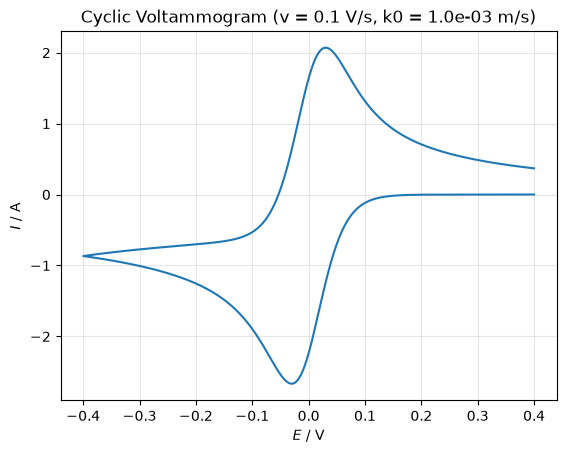

In [3]:
ox = Species("Ox", diffusivity=D, bulk_concentration=c_bulk, standard_potential=E0, n_electrons=1)
red = Species("Red", diffusivity=D, bulk_concentration=0.0)

cv = CyclicVoltammetry(E_start=E_start, E_vertex1=E_vertex1, E_vertex2=E_vertex2, scan_rate=v)
kinetics = ButlerVolmer(k0=k0, alpha=alpha, E0=E0, n=1)

result = simulate(cv, [ox, red], kinetics=kinetics)

fig, ax = plot_result(result)
ax.set_title(f"Cyclic Voltammogram (v = {v} V/s, k0 = {k0:.1e} m/s)")
plt.show()

## 4. Compare Peak Current with Randles–Ševčík Theory

In [4]:
ip_sim = result.current.min()
ip_rs = spa.randles_sevcik(v, c_bulk=c_bulk, D=D, area=1.0, n=1)
print(f"Simulated cathodic peak:      {ip_sim:.3f} A/m^2")
print(f"Randles-Sevcik reversible:    {ip_rs:.3f} A/m^2")

Simulated cathodic peak:      -2.667 A/m^2
Randles-Sevcik reversible:    -2.686 A/m^2


## 5. Explore Reversible vs. Quasi-Reversible Kinetics

Lowering $k^0$ increases the peak-to-peak separation $\Delta E_p$ and decreases peak current.

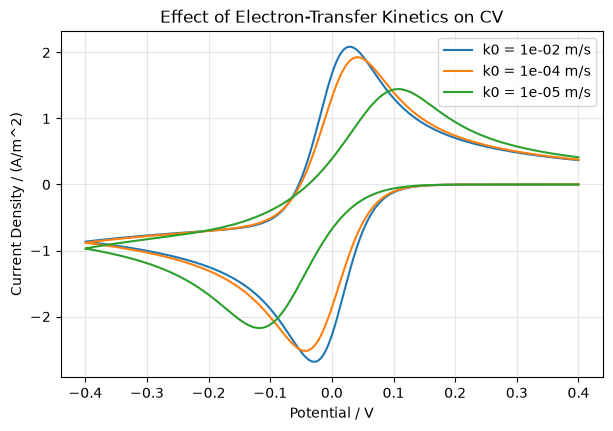

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for k0_val in [1.0e-2, 1.0e-4, 1.0e-5]:
    res = simulate(cv, [ox, red], kinetics=ButlerVolmer(k0=k0_val, alpha=alpha, E0=E0, n=1))
    ax.plot(res.potential, res.current, label=f"k0 = {k0_val:.0e} m/s")

ax.set(xlabel="Potential / V", ylabel="Current Density / (A/m^2)", title="Effect of Electron-Transfer Kinetics on CV")
ax.legend()
ax.grid(alpha=0.3)
plt.show()